detect the alphabetical ordered paper

In [1]:
import pandas as pd

In [2]:
article_path = '../../data/dropbox/LaborDivision/Data/cleanedraw/articles.pkl'
author_path = '../../data/dropbox/LaborDivision/Data/cleanedraw/authors.pkl'
dis_path = '../../data/dropbox/LaborDivision/Data/rawdata/discipline_code.csv'
coauthor_path = '../../data/dropbox/LaborDivision/Data/rawdata/art_cntry_corr.txt'

In [202]:
author_df=pd.read_pickle(author_path)
author_df.head()

,id,full,first,last,seqno,addrno,cntry
0,79079869,"Tudor, M. Scarlett",M. Scarlett,Tudor,2,3,USA
1,30989949,"Tunney, J. J.",J. J.,Tunney,4,1,Canada
2,30743826,"Kim, Keon-Hee",Keon-Hee,Kim,2,2,South Korea
3,55406282,"Biron, David",David,Biron,6,3,USA
4,74854337,"Fortunato, Santo",Santo,Fortunato,2,1,Italy


In [40]:
pub_df=pd.read_pickle(article_path)
pub_df.head()

,id,year,dis
0,38579295,2012,1
1,38579296,2012,120
3,38579302,2012,55
4,38579305,2012,43
6,38579321,2012,51


In [74]:
order_df =  author_df.sort_values(by=['id','seqno','addrno']
                                 ).drop_duplicates(subset=['id','seqno'],keep='first')

In [5]:
order_df.head(30).groupby(['id'])['last'].apply(list).reset_index()

,id,last
0,29768068,"[Miron, Hall, Antel]"
1,29768070,"[Shen, Tanida, Yao, Niijima, Nagai]"
2,29768083,"[Ershov, Morozov]"
3,29768087,"[Kozlova, Balakhonov, Goodilin, Churagulov, Ve..."
4,29768097,"[Hao, Lin, Song, Lin, Su, Qu]"
5,29768104,"[Boll, Merkle, Paulson, Hoffmann]"
6,29768112,"[Ferri, Pampana, Sansonno, Antonelli]"


In [6]:
alpha_df=order_df.groupby(['id'])['last'].apply(list).reset_index()

In [7]:
alpha_df.head()

,id,last
0,29768068,"[Miron, Hall, Antel]"
1,29768070,"[Shen, Tanida, Yao, Niijima, Nagai]"
2,29768083,"[Ershov, Morozov]"
3,29768087,"[Kozlova, Balakhonov, Goodilin, Churagulov, Ve..."
4,29768097,"[Hao, Lin, Song, Lin, Su, Qu]"


In [25]:
def alpha_order(namelist):
    if(len(namelist)<4):
        return "null"
    else:
        nlist=namelist[:6]
        return all(nlist[i] <= nlist[i+1] for i in range(len(nlist) - 1))

In [29]:
alpha_df['alpha']=alpha_df['last'].apply(lambda x:alpha_order(x))

In [31]:
alpha_df[alpha_df.alpha==True]

,id,last,alpha
117,29768507,"[Borges, Ferraz, Terra-Filho, Vianna]",True
138,29768575,"[Del Sordo, Leite, Petroni, Sidoni]",True
211,29768885,"[Belboukhari, Cheriti, Djafri, Roussel]",True
271,29769152,"[Hodge, Janus, Sundararajan, Taylor]",True
300,29769262,"[Meissner, Rakhimov, Wirzba, Yakhshiev]",True
...,...,...,...
18929740,84634437,"[Benkart, Kang, Oh, Park]",True
18929814,84634528,"[Borndoerfer, Esser, Frankenberger, Huck, Jobm...",True
18929830,84634548,"[Atienza, Bielza, Diaz-Rozo, Larranaga]",True
18929908,84634640,"[Jiang, Jiao, Tian, Zhang]",True


In [48]:
dis_df=pd.read_csv(dis_path,header=0,names=['dis','disname'],dtype = {'dis':'str'})
dis_df.head()

,dis,disname
0,1,Agricult & Food Science
1,2,Botany
2,3,Dairy & Animal Science
3,4,Ecology
4,5,Entomology


In [ ]:
alpha_df=alpha_df.merge(pub_df,on='id')

In [50]:
alpha_df = alpha_df.merge(dis_df,on='dis')

In [51]:
alpha_df.head()

,id,last,alpha,year,dis,disname
0,29768068,"[Miron, Hall, Antel]",null,2008,56,Pathology
1,29768981,"[Rouzic, Faisant, Scheydeker, Collet, Lejeune]",False,2008,56,Pathology
2,29770405,"[Syed, Martin, Haupt, Podolski, Brooks]",False,2008,56,Pathology
3,29771817,"[Ramos, Salvatti, Cipriano, Roriz-Filho, Matos...",False,2008,56,Pathology
4,29774439,"[McCluggage, Shah, Connolly, McBride]",False,2008,56,Pathology


In [54]:
res_df = alpha_df.groupby(['disname','alpha']).size().reset_index(name='count')
res_df = res_df.pivot(index='disname',columns=['alpha'],values='count')

In [62]:
res_df.columns = res_df.columns.astype(str)

In [63]:
res_df.columns

Index(['False', 'True', 'null'], dtype='object', name='alpha')

In [66]:
res_df['total']=res_df['False']+res_df['True']+res_df['null']
res_df['cal_p']=(res_df['False']+res_df['True'])/res_df['total']
res_df['order_p']=res_df['True']/(res_df['False']+res_df['True'])

In [74]:
res_df = res_df.sort_values(by='order_p',ascending=False)

In [75]:
res_df.head()

alpha,False,True,null,total,cal_p,order_p
disname,,,,,,
General Mathematics,11612,11361,226006,248979,0.092269,0.494537
Miscellaneous Mathematics,1845,1712,19238,22795,0.156043,0.481304
Nuclear & Particle Physics,31791,19186,85370,136347,0.373877,0.376366
History,560,187,47929,48676,0.015346,0.250335
Philosophy,210,69,32209,32488,0.008588,0.247312


In [76]:
alpha_df.head()

,id,last,alpha,year,dis,disname
0,29768068,"[Miron, Hall, Antel]",null,2008,56,Pathology
1,29768981,"[Rouzic, Faisant, Scheydeker, Collet, Lejeune]",False,2008,56,Pathology
2,29770405,"[Syed, Martin, Haupt, Podolski, Brooks]",False,2008,56,Pathology
3,29771817,"[Ramos, Salvatti, Cipriano, Roriz-Filho, Matos...",False,2008,56,Pathology
4,29774439,"[McCluggage, Shah, Connolly, McBride]",False,2008,56,Pathology


In [88]:
alpha_df['size']=alpha_df.apply(lambda x:len(x['last']),axis=1)

In [91]:
two = alpha_df[alpha_df['size']==2]
two['alpha']=two.apply(lambda x: "True" if x['last'][0]<x['last'][1] else 'False',axis=1)

<ipython-input-91-cd7344191e00>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  two['alpha']=two.apply(lambda x: "True" if x['last'][0]<x['last'][1] else 'False',axis=1)


In [94]:
two = two.groupby(['disname','alpha']).size()
two = two.reset_index(name='count')

In [97]:
two = two.pivot(index='disname',columns='alpha',values='count')

In [99]:
two['true_p']=two['True']/(two['False']+two['True'])

In [114]:
meta = res_df.merge(two[['total2','true_p']],left_index=True,right_index=True)

In [116]:
meta['total2_p']=meta['total2']/meta['total']

In [157]:
meta = meta.reset_index()

In [173]:
meta[(meta.order_p>0.42)|(meta.true_p>0.55)]

alpha,disname,False,True,null,total,cal_p,order_p,total2,true_p,total2_p
0,General Mathematics,11612,11361,226006,248979,0.092269,0.494537,114127,0.821059,0.458380
1,Miscellaneous Mathematics,1845,1712,19238,22795,0.156043,0.481304,9645,0.818040,0.423119
2,Nuclear & Particle Physics,31791,19186,85370,136347,0.373877,0.376366,35923,0.771261,0.263467
3,History,560,187,47929,48676,0.015346,0.250335,7227,0.650062,0.148472
4,Philosophy,210,69,32209,32488,0.008588,0.247312,4189,0.660778,0.128940
5,Economics,21502,6498,151639,179639,0.155868,0.232071,72504,0.754979,0.403609
6,International Relations,439,115,15615,16169,0.034263,0.207581,5368,0.679955,0.331993
7,Literature,135,34,38667,38836,0.004352,0.201183,2895,0.633161,0.074544
8,Applied Mathematics,39250,9692,154473,203415,0.240602,0.198030,74696,0.684160,0.367210
9,Probability & Statistics,11763,2668,69235,83666,0.172483,0.184880,34502,0.669468,0.412378


remove pubs in this disciplines

In [181]:
dislist = meta[(meta.order_p>0.42)|(meta.true_p>0.55)].disname
dislist = dis_df[dis_df.disname.isin(dislist)].dis.tolist()

In [185]:
pub_df = pub_df[~pub_df.dis.isin(dislist)]

remove pubs that are high likely to be alphabetically ordered

In [192]:
alphaid = alpha_df[alpha_df.alpha==True].id.tolist()

In [194]:
pub_df = pub_df[~pub_df['id'].isin(alphaid)]

In [196]:
pub_df.shape

(16670379, 3)

In [199]:
16670379/18930171

0.8806248501400225

In [209]:
cntry_df = order_df[order_df['id'].isin(pub_df['id'])]

In [ ]:
order_df[order_df['id'].isin(pub_df['id'])].to_pickle("cntry_df.pkl")

In [ ]:
pub_df.to_pickle('pub_df.pkl')

In [213]:
cntry_df = cntry_df.groupby(['id'],sort=False)['cntry'].apply(list).reset_index()

In [225]:
ids='38579414'
order_df[order_df['id']==ids]

,id,full,first,last,seqno,addrno,cntry
129988169,38579414,"Yurube, Takashi",Takashi,Yurube,1,1,Japan
121170750,38579414,"Takada, Toru",Toru,Takada,2,1,Japan
97590543,38579414,"Suzuki, Teppei",Teppei,Suzuki,3,1,Japan
65449221,38579414,"Kakutani, Kenichiro",Kenichiro,Kakutani,4,1,Japan
82591378,38579414,"Maeno, Koichiro",Koichiro,Maeno,5,1,Japan
116618962,38579414,"Doita, Minoru",Minoru,Doita,6,1,Japan
138287075,38579414,"Kurosaka, Masahiro",Masahiro,Kurosaka,7,1,Japan
37625517,38579414,"Nishida, Kotaro",Kotaro,Nishida,8,1,Japan


In [12]:
cntry_df = pd.read_pickle('cntry_df.pkl')

In [13]:
pub_df = pd.read_pickle('pub_df.pkl')

In [7]:
pub_df.head()

,id,year,dis
0,38579295,2012,1
3,38579302,2012,55
4,38579305,2012,43
6,38579321,2012,51
7,38579327,2012,135


In [30]:
cntrys = cntry_df[['cntry']].drop_duplicates()

In [2]:
flag_path = "../../data/dropbox/LaborDivision/Data/additionaldata/country_WoS_ECI_WB_flags.tsv"
flag_df=pd.read_csv(flag_path, sep="\t")
flag_df.head()

,WoS,ECI_Country,WB,Code
0,Albania,Albania,Albania,ALB
1,Algeria,Algeria,Algeria,DZA
2,Angola,Angola,Angola,AGO
3,Argentina,Argentina,Argentina,ARG
4,Australia,Australia,Australia,AUS


In [4]:
cntry_path='cntry_convert.csv'
cntry_df=pd.read_csv(cntry_path,names=['cntry','WoS'])

In [8]:
cntry_df=cntry_df.merge(flag_df[['WoS','Code']],on='WoS',how='left')

In [10]:
cntry_df.to_csv('cntry_convert.csv')

In [16]:
cntry_map=pd.read_csv('cntry_convert.csv')
cntry_map.head()

,cntry,WoS,Code
0,Afghanistan,Afghanistan,AFG
1,Albania,Albania,ALB
2,Algeria,Algeria,DZA
3,Andorra,Andorra,AND
4,Angola,Angola,AGO


In [14]:
cntry_df.head()

,id,full,first,last,seqno,addrno,cntry
73975812,29768068,"Miron, Veronique E.",Veronique E.,Miron,1,1,Canada
33349838,29768068,"Hall, Jeffery A.",Jeffery A.,Hall,2,3,Canada
63107318,29768068,"Antel, Jack P.",Jack P.,Antel,5,1,Canada
104894541,29768070,"Shen, Jiao",Jiao,Shen,1,1,Japan
25768024,29768070,"Tanida, Mamoru",Mamoru,Tanida,2,1,Japan


In [19]:
cntrydict=dict(zip(cntry_map.cntry,cntry_map.Code))

In [20]:
cntry_df['code']=cntry_df['cntry'].map(cntrydict)

In [21]:
cntry_df

,id,full,first,last,seqno,addrno,cntry,code
73975812,29768068,"Miron, Veronique E.",Veronique E.,Miron,1,1,Canada,CAN
33349838,29768068,"Hall, Jeffery A.",Jeffery A.,Hall,2,3,Canada,CAN
63107318,29768068,"Antel, Jack P.",Jack P.,Antel,5,1,Canada,CAN
104894541,29768070,"Shen, Jiao",Jiao,Shen,1,1,Japan,JPN
25768024,29768070,"Tanida, Mamoru",Mamoru,Tanida,2,1,Japan,JPN
...,...,...,...,...,...,...,...,...
52765329,84634948,"Zhang, Xinshuo",Xinshuo,Zhang,2,1,Peoples R China,CHN
106629262,84634948,"Quan, Li",Li,Quan,3,3,Peoples R China,CHN
62849462,84634949,"Ochola, Elizabeth A.",Elizabeth A.,Ochola,1,1,Canada,CAN
99674311,84634949,"Karanja, Diana M. S.",Diana M. S.,Karanja,2,2,Kenya,KEN


In [72]:
cntry_df = cntry_df.dropna()
cntry_df.to_pickle('cntry_df.pkl')

In [26]:
intcol = cntry_df.groupby(['id'])['code'].apply(list).reset_index(name='cntrys')

In [29]:
intcol['cntry_distinct']=intcol['cntrys'].apply(lambda x:list(set(x)))

In [31]:
intcol['numcntry']=intcol['cntry_distinct'].apply(lambda x:len(x))

In [73]:
intcol.to_pickle('intcol_df.pkl')

In [ ]:
cntry_df=pd.read_pickle('cntry_df.pkl')

In [3]:
intcol=pd.read_pickle('intcol_df.pkl')

In [4]:
intcol.head()

,id,cntrys,cntry_distinct,numcntry
0,29768068,"[CAN, CAN, CAN]",[CAN],1
1,29768070,"[JPN, JPN, CHN, JPN, JPN]","[CHN, JPN]",2
2,29768083,"[RUS, RUS]",[RUS],1
3,29768087,"[RUS, RUS, RUS, RUS, RUS, RUS]",[RUS],1
4,29768097,"[CHN, CHN, CHN, CHN, CHN, CHN]",[CHN],1


In [5]:
cntry_df.head()

,id,full,first,last,seqno,addrno,cntry,code
73975812,29768068,"Miron, Veronique E.",Veronique E.,Miron,1,1,Canada,CAN
33349838,29768068,"Hall, Jeffery A.",Jeffery A.,Hall,2,3,Canada,CAN
63107318,29768068,"Antel, Jack P.",Jack P.,Antel,5,1,Canada,CAN
104894541,29768070,"Shen, Jiao",Jiao,Shen,1,1,Japan,JPN
25768024,29768070,"Tanida, Mamoru",Mamoru,Tanida,2,1,Japan,JPN


#### id of paper which paper is international coauthored

In [6]:
colid=intcol[intcol.numcntry>1].id.tolist()

In [10]:
col_df=cntry_df[cntry_df['id'].isin(colid)]

In [11]:
col_df.head()

,id,full,first,last,seqno,addrno,cntry,code
104894541,29768070,"Shen, Jiao",Jiao,Shen,1,1,Japan,JPN
25768024,29768070,"Tanida, Mamoru",Mamoru,Tanida,2,1,Japan,JPN
125210780,29768070,"Yao, Jia-fei",Jia-fei,Yao,3,3,Peoples R China,CHN
114298031,29768070,"Niijima, Akira",Akira,Niijima,4,4,Japan,JPN
110968478,29768070,"Nagai, Katsuya",Katsuya,Nagai,5,1,Japan,JPN


In [12]:
first_df=col_df[col_df.seqno==1]

In [13]:
first_df.head()

,id,full,first,last,seqno,addrno,cntry,code
104894541,29768070,"Shen, Jiao",Jiao,Shen,1,1,Japan,JPN
117365266,29768104,"Boll, Daniel T.",Daniel T.,Boll,1,1,USA,USA
143633475,29768123,"Cloutis, Edward A.",Edward A.,Cloutis,1,1,Canada,CAN
80738456,29768126,"Emilsson, Valur",Valur,Emilsson,1,1,Iceland,ISL
86961572,29768150,"Zhao, Jinsheng",Jinsheng,Zhao,1,1,Peoples R China,CHN


In [14]:
ingroup=pd.read_csv('cntry_year_incomegroup.csv')
ingroup=ingroup[ingroup.YEAR=='2013-2017']

In [15]:
ingroup.head()

,Code,IncomeGroup,YEAR,WoS
5,AFG,L,2013-2017,Afghanistan
11,ALB,UM,2013-2017,Albania
17,DZA,UM,2013-2017,Algeria
23,AND,H,2013-2017,Andorra
29,AGO,UM,2013-2017,Angola


In [16]:
ingroupdict=dict(zip(ingroup['Code'],ingroup.IncomeGroup))

In [17]:
first_df['ingroup']=first_df['code'].map(ingroupdict)

<ipython-input-17-f288d230fc78>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  first_df['ingroup']=first_df['code'].map(ingroupdict)


In [21]:
pub_df=pd.read_pickle('pub_df.pkl')

In [22]:
first_df=first_df.merge(pub_df,on='id')

In [24]:
tt = first_df.groupby(['year','ingroup']).size().reset_index(name='count')
tt=tt.pivot(index='year',columns='ingroup',values='count')
tt = tt.div(tt.sum(axis=1), axis=0)

In [26]:
tt

ingroup,H,L,LM,UM
year,,,,
2008,0.785467,0.004806,0.042644,0.167083
2009,0.773809,0.005061,0.044921,0.176209
2010,0.765523,0.005602,0.046790,0.182085
2011,0.753739,0.005566,0.047297,0.193398
2012,0.748191,0.005335,0.046327,0.200148
2013,0.730273,0.005403,0.046946,0.217379
2014,0.712560,0.006071,0.049570,0.231799
2015,0.698363,0.005990,0.050136,0.245511
2016,0.681638,0.005825,0.052776,0.259760


In [28]:
lastid=intcol[intcol.numcntry>2]['id'].tolist()

In [30]:
cntry_df.head()

,id,full,first,last,seqno,addrno,cntry,code
73975812,29768068,"Miron, Veronique E.",Veronique E.,Miron,1,1,Canada,CAN
33349838,29768068,"Hall, Jeffery A.",Jeffery A.,Hall,2,3,Canada,CAN
63107318,29768068,"Antel, Jack P.",Jack P.,Antel,5,1,Canada,CAN
104894541,29768070,"Shen, Jiao",Jiao,Shen,1,1,Japan,JPN
25768024,29768070,"Tanida, Mamoru",Mamoru,Tanida,2,1,Japan,JPN


In [31]:
last_df=cntry_df[cntry_df.id.isin(lastid)]

In [33]:
last_df=last_df.drop_duplicates(subset='id',keep='last')

In [37]:
last_df['ingroup']=last_df['code'].map(ingroupdict)

In [39]:
last_df=last_df.merge(pub_df,on='id')

In [40]:
last_df.head()

,id,full,first,last,seqno,addrno,cntry,code,ingroup,year,dis
0,29768191,"Ho, Anthony M-H.",Anthony M-H.,Ho,6,2,Peoples R China,CHN,UM,2008,44
1,29768270,"Louis, Edward E.",Edward E.,Louis,6,6,USA,USA,H,2008,66
2,29768372,"Shinyashiki, N.",N.,Shinyashiki,3,4,Japan,JPN,H,2008,31
3,29768548,"Rebek, Julius, Jr.",Julius,Rebek,5,1,USA,USA,H,2008,30
4,29768961,"Heimann, M.",M.,Heimann,18,1,Germany,DEU,H,2008,71


In [41]:
bb = last_df.groupby(['year','ingroup']).size().reset_index(name='count')
bb=bb.pivot(index='year',columns='ingroup',values='count')
bb = bb.div(bb.sum(axis=1), axis=0)

In [44]:
bb.reset_index()

ingroup,year,H,L,LM,UM
0,2008,0.890213,0.005757,0.024856,0.079174
1,2009,0.890770,0.005053,0.024773,0.079403
2,2010,0.883788,0.005783,0.025846,0.084583
3,2011,0.879963,0.006194,0.028183,0.085659
4,2012,0.878702,0.005843,0.026822,0.088633
5,2013,0.873168,0.005666,0.027311,0.093855
6,2014,0.861814,0.005877,0.030687,0.101622
7,2015,0.854245,0.005569,0.031689,0.108497
8,2016,0.844440,0.005854,0.033715,0.115991
9,2017,0.833319,0.006377,0.035338,0.124965


In [46]:
bb = bb.reset_index().melt(id_vars='year', var_name='ingroup', value_name='value')
tt = tt.reset_index().melt(id_vars='year', var_name='ingroup', value_name='value')

In [52]:
tt = tt[tt.year!=2022]
bb = bb[bb.year!=2022]

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

<AxesSubplot:xlabel='year', ylabel='value'>

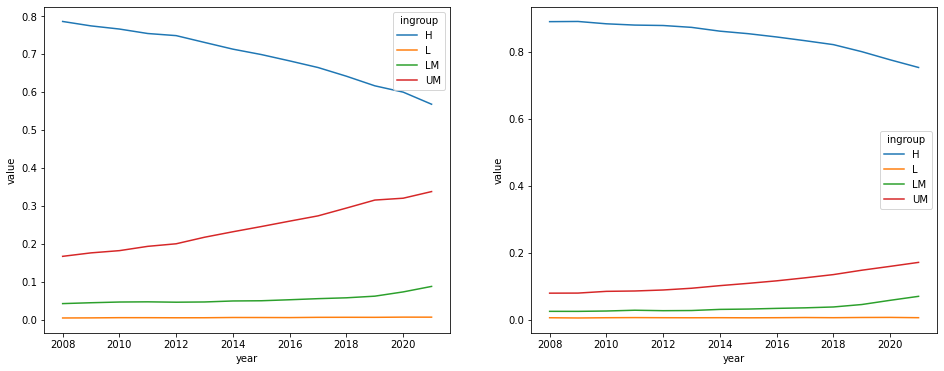

In [57]:
fig, ax=plt.subplots(nrows=1,ncols=2,figsize=(16,6))
sns.lineplot(x='year',y='value',hue='ingroup',data=tt,ax=ax[0])
sns.lineplot(x='year',y='value',hue='ingroup',data=bb,ax=ax[1])

In [64]:
col_df['ingroup']=col_df['code'].map(ingroupdict)
col_df=col_df.merge(pub_df,on='id')

<ipython-input-64-6dbd00b90e91>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  col_df['ingroup']=col_df['code'].map(ingroupdict)


In [71]:
col_df['ingroup'].unique()

array(['H', 'UM', 'L', 'LM', nan], dtype=object)

In [76]:
ids = col_df[col_df.ingroup=='UM']['id'].unique()
df = col_df[col_df.id.isin(ids)]
ff =df[df.seqno==1]
tt = ff.groupby(['year','ingroup']).size().reset_index(name='count')
tt=tt.pivot(index='year',columns='ingroup',values='count')
tt = tt.div(tt.sum(axis=1), axis=0)
tt = tt.reset_index().melt(id_vars='year', var_name='ingroup', value_name='value')
tt = tt[tt.year!=2022]

ll=df[df.id.isin(lastid)]
ll=ll.drop_duplicates(subset='id',keep='last')
bb = ll.groupby(['year','ingroup']).size().reset_index(name='count')
bb=bb.pivot(index='year',columns='ingroup',values='count')
bb = bb.div(bb.sum(axis=1), axis=0)
bb = bb.reset_index().melt(id_vars='year', var_name='ingroup', value_name='value')
bb = bb[bb.year!=2022]

<AxesSubplot:xlabel='year', ylabel='value'>

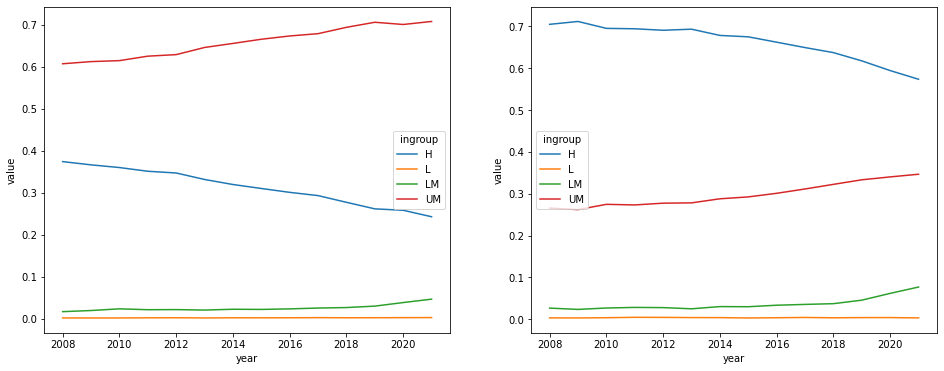

In [77]:
fig, ax=plt.subplots(nrows=1,ncols=2,figsize=(16,6))
sns.lineplot(x='year',y='value',hue='ingroup',data=tt,ax=ax[0])
sns.lineplot(x='year',y='value',hue='ingroup',data=bb,ax=ax[1])